# Tugas Praktikum - Multiple Linear Regression (Medical Cost Personal Datasets)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** Regresi

### Deskripsi Tugas:
Membangun model **Multiple Linear Regression** pada dataset `insurance.csv` untuk memprediksi besarnya tagihan biaya medis personal (`charges`).

**Instruksi Pengerjaan:**
1. Identifikasi variabel bebas (fitur) dan variabel target (`charges`).
2. Membagi dataset menjadi data latih (*train*) dan data uji (*test*) dengan proporsi yang sesuai (80:20).
3. Melakukan *feature encoding* (One-Hot / Binary Encoding) dan *feature scaling* (`StandardScaler`).
4. Membangun model Multiple Linear Regression menggunakan Scikit-Learn.
5. Melatih model pada data latih dan melakukan prediksi pada data uji.
6. Mengevaluasi model dengan menghitung $R^2$, MSE, RMSE, dan MAE serta menyajikan visualisasi analisis residual.

## Langkah 1 - Import Library

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='whitegrid')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Langkah 2 - Memuat dan Memahami Dataset Medical Cost

In [2]:
data_path = r'..\Dataset\insurance.csv'

df_ins = pd.read_csv(data_path)
print('Dimensi data:', df_ins.shape)
df_ins.head()

Dimensi data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df_ins.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [4]:
df_ins.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Langkah 3 - Analisis Eksploratif dan Visualisasi Data (EDA)

C:\Users\luvma\AppData\Local\Temp\ipykernel_14232\1097045563.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoker', y='charges', data=df_ins, ax=axes[2], palette='Set2')


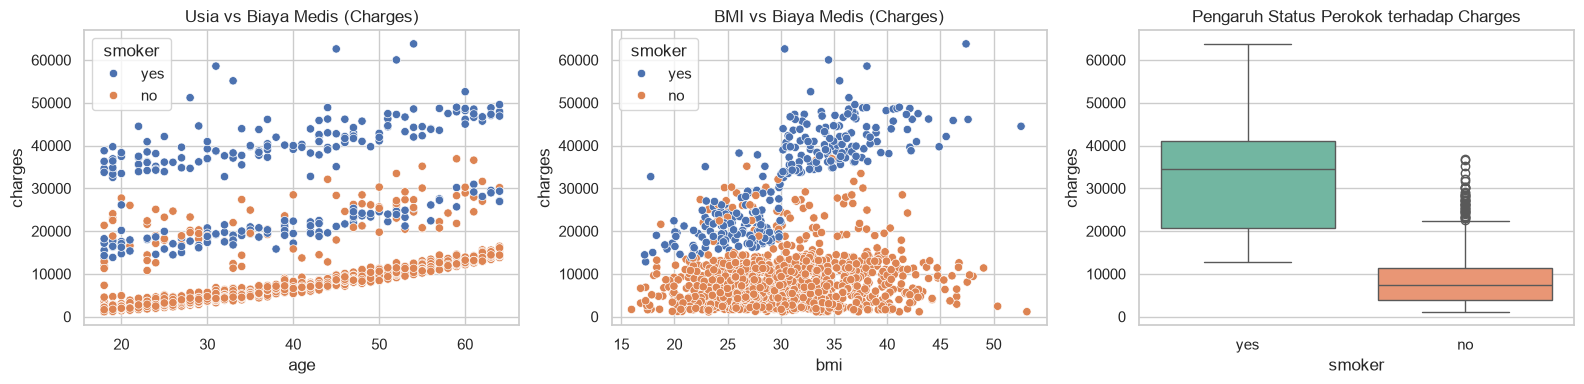

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.scatterplot(x='age', y='charges', hue='smoker', data=df_ins, ax=axes[0])
axes[0].set_title('Usia vs Biaya Medis (Charges)')

sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df_ins, ax=axes[1])
axes[1].set_title('BMI vs Biaya Medis (Charges)')

sns.boxplot(x='smoker', y='charges', data=df_ins, ax=axes[2], palette='Set2')
axes[2].set_title('Pengaruh Status Perokok terhadap Charges')

plt.tight_layout()
plt.show()

## Langkah 4 - Pra Pengolahan Data (Encoding Variabel Kategorikal)
Variabel kategorikal yang perlu di-encode:
- `sex`: female/male -> binary 0/1
- `smoker`: no/yes -> binary 0/1 (faktor paling signifikan)
- `region`: southwest, southeast, northwest, northeast -> One-Hot Encoding

In [6]:
# Encoding variabel biner
df_encoded = df_ins.copy()
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})

# One-Hot Encoding untuk region
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True, dtype=int)
print('Fitur setelah encoding:')
df_encoded.head()

Fitur setelah encoding:


,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


## Langkah 5 - Pembagian Data Latih dan Data Uji (80:20) serta Feature Scaling

In [7]:
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standarisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Ukuran data latih (X_train): {X_train.shape}')
print(f'Ukuran data uji (X_test):   {X_test.shape}')

Ukuran data latih (X_train): (1070, 8)
Ukuran data uji (X_test):   (268, 8)


## Langkah 6 - Pelatihan Model Multiple Linear Regression

In [8]:
model_lr = LinearRegression()
model_lr.fit(X_train_scaled, y_train)

# Menampilkan koefisien regresi tiap fitur
coef_df = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model_lr.coef_
}).sort_values(by='Koefisien', ascending=False)

print(f'Intercept (Konstanta): Rp {model_lr.intercept_:,.2f}')
print('\nKontribusi Koefisien Fitur terhadap Tagihan Medis:')
print(coef_df.to_string(index=False))

Intercept (Konstanta): Rp 13,346.09

Kontribusi Koefisien Fitur terhadap Tagihan Medis:
           Fitur   Koefisien
          smoker 9558.481409
             age 3614.975415
             bmi 2036.228123
        children  516.890247
             sex   -9.293101
region_northwest -158.140981
region_southeast -290.157047
region_southwest -349.110678


## Langkah 7 - Prediksi dan Evaluasi Model pada Data Uji

In [9]:
y_pred = model_lr.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('=== Hasil Evaluasi Model Multiple Linear Regression ===')
print(f'R-squared (R2)              : {r2:.4f} ({r2*100:.2f}% variansi dijelaskan oleh model)')
print(f'Mean Absolute Error (MAE)    : Rp {mae:,.2f}')
print(f'Mean Squared Error (MSE)     : {mse:,.2f}')
print(f'Root Mean Squared Error(RMSE): Rp {rmse:,.2f}')

=== Hasil Evaluasi Model Multiple Linear Regression ===
R-squared (R2)              : 0.7836 (78.36% variansi dijelaskan oleh model)
Mean Absolute Error (MAE)    : Rp 4,181.19
Mean Squared Error (MSE)     : 33,596,915.85
Root Mean Squared Error(RMSE): Rp 5,796.28


## Langkah 8 - Visualisasi Hasil Prediksi vs Aktual dan Residual Plot

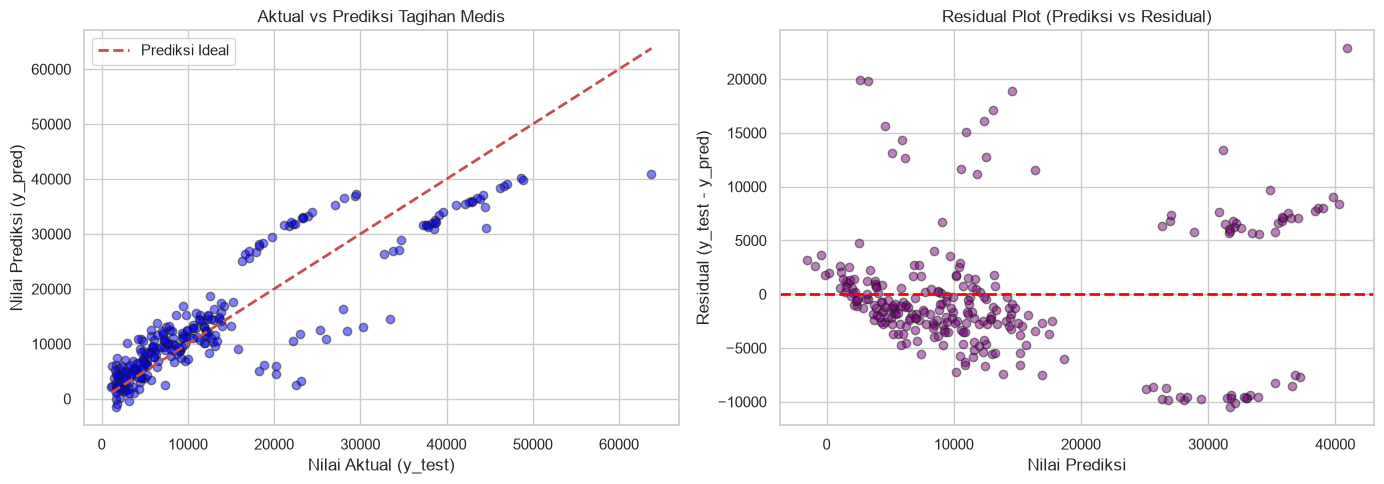

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot Aktual vs Prediksi
axes[0].scatter(y_test, y_pred, color='blue', alpha=0.5, edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Prediksi Ideal')
axes[0].set_title('Aktual vs Prediksi Tagihan Medis')
axes[0].set_xlabel('Nilai Aktual (y_test)')
axes[0].set_ylabel('Nilai Prediksi (y_pred)')
axes[0].legend()

# Residual plot
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, color='purple', alpha=0.5, edgecolors='k')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residual Plot (Prediksi vs Residual)')
axes[1].set_xlabel('Nilai Prediksi')
axes[1].set_ylabel('Residual (y_test - y_pred)')

plt.tight_layout()
plt.show()

## Analisis dan Kesimpulan Tugas Praktikum JS06 Regresi
1. **Faktor Paling Berpengaruh**: Berdasarkan bobot koefisien regresi, status perokok (`smoker`) memiliki pengaruh paling masif dan dominan (koefisien ~ Rp 9.558) terhadap kenaikan biaya tagihan medis, diikuti oleh indeks massa tubuh (`bmi`) dan usia (`age`).
2. **Akurasi Model**: Model Multiple Linear Regression mencapai nilai $R^2$ sebesar **0.7836** pada data uji yang tidak pernah dilihat sebelumnya, menunjukkan bahwa sekitar 78.4% variabilitas tagihan medis personal berhasil dijelaskan oleh kombinasi fitur-fitur independen ini.
3. **Metrik Error**: Rata-rata deviasi absolut (MAE) model adalah sekitar Rp 4.181, yang merupakan batas toleransi wajar untuk estimasi premi asuransi kesehatan personal.